# vibecheck: judge a Spotify playlist

Paste a playlist link and get a Wrapped-style read on it: **mood**, **estimated age**, **listening personality**,
**lyrical themes**, a **roast**, and (with your data export) **how and when you listen**, plus two small ML
models you can train and evaluate.

**How it works**

| Signal | Source | Used for |
|---|---|---|
| Tracks, artists, genres, release dates, ISRCs | Spotify Web API (your own app, PKCE login) | everything |
| Valence, energy, danceability, tempo... | [ReccoBeats](https://reccobeats.com) (Spotify removed its audio-features endpoint for new apps in Nov 2024) | mood |
| Lyrics | [LRCLIB](https://lrclib.net) | emotion + theme NLP |
| Crowd mood tags (optional) | Last.fm | mood, genre fallback |
| Listening history (optional) | Spotify privacy export | behaviour, mood over time |

**Honest caveats, up front**
- Spotify Development Mode (Feb 2026 rules) only returns tracks for playlists **you own or collaborate on**,
  needs Premium, and caps an app at 5 users. Paste a link to someone else's playlist and you'll get a message
  with workarounds (copy it into your own playlist, or load a CSV export).
- The "mental health" part is deliberately framed as **emotional tone of the music**, compared against your
  own baseline. Music is a weak, noisy signal of how a person is doing; nothing here is diagnostic.
- With `DEMO = True` everything runs offline on synthetic data (made-up artists and lyrics), so you can see
  every output before connecting Spotify.

In [1]:
DEMO = True        # flip to False once .env has SPOTIFY_CLIENT_ID (see README)
PLAYLIST = "https://open.spotify.com/playlist/REPLACE_ME"   # a playlist you own or collaborate on
TZ = "America/New_York"                                      # for listening-time stats

import sys
from pathlib import Path
try:
    import vibecheck
except ImportError:                       # running from the repo without `pip install -e .`
    sys.path.insert(0, str(Path.cwd().parent))
    import vibecheck

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from vibecheck import Vibecheck, load_streaming_history, load_tracks_csv
from vibecheck import report
from vibecheck.demo import demo_playlist, demo_history, demo_labelled_playlists, demo_age_samples

pd.set_option("display.max_colwidth", 60)
%matplotlib inline
vc = Vibecheck(offline=DEMO)

## 1. Load a playlist

`vc.load()` accepts playlist / album / track links, `spotify:` URIs, or the keywords `"liked"`, `"top"`,
`"top:short_term"`, `"recent"`. The first real call opens a browser tab for the Spotify login; the token is
cached in `~/.vibecheck/`.

Got a CSV instead (e.g. Chosic's playlist-analyzer export, Exportify, a spreadsheet)? Use
`load_tracks_csv("file.csv")`; it matches column names loosely and keeps any audio-feature columns.

In [2]:
if DEMO:
    meta = {"kind": "playlist", "name": "Demo: sad hours"}
    raw = demo_playlist()
else:
    meta, raw = vc.load(PLAYLIST)
    # meta, raw = {"kind": "csv", "name": "my export"}, load_tracks_csv("my_export.csv")

print(meta)
raw[["name", "artists", "album", "release_date", "duration_ms", "explicit"]].head()

{'kind': 'playlist', 'name': 'Demo: sad hours'}


,name,artists,album,release_date,duration_ms,explicit
0,Echo Velvet,[Neon Hymnal],Weather Sessions,2024-02-06,172698,True
1,Honey Weather,[Kilo Sunday],Glass Hours,2019-02-16,192852,True
2,Bloom Ember,[Kilo Sunday],Velvet Hours,2021-03-06,135156,False
3,Orchard Velvet,[Ash & Ivory],River Tapes,2019-08-03,183428,False
4,Midnight Harbor,[The Paper Moths],Paper Sessions,2014-10-21,144460,False


## 2. Enrich

One call adds: release year (earliest of album date and the year code inside the ISRC, which survives
remasters and compilations), artist genres to macro genres, ReccoBeats audio features, Last.fm tags (if
`LASTFM_API_KEY` is set), LRCLIB lyrics, lyric NLP, and a blended per-track mood. Everything is cached in SQLite,
so re-runs are fast.

In [3]:
tracks = vc.enrich(raw)
coverage = {
    "audio features": tracks["valence"].notna().mean(),
    "lyrics": tracks.get("has_lyrics", pd.Series(False)).mean(),
    "genres": tracks["macro_genres"].map(bool).mean(),
    "release year": tracks["release_year"].notna().mean(),
}
pd.Series(coverage, name="coverage").map("{:.0%}".format)

[vibecheck] scoring lyrics (lexicon emotion model)


audio features    100%
lyrics             95%
genres            100%
release year      100%
Name: coverage, dtype: str

## 3. The verdict

In [4]:
profile = vc.analyze(tracks, meta=meta)
display(Markdown(profile.summary()))

## Demo: sad hours: The 3 A.M. Drive Specialist

**Verdict:** The 3 A.M. Drive Specialist. Leans Punk/Emo, centred on 2019, with an angsty streak.

| | |
|---|---|
| Mood | Angsty (intense, restless, a little stormy); valence 0.40, arousal 0.54 |
| Estimated age | ~27 years old (80% interval 24-30, from 37 release years) |
| Era | median 2019, mostly the 2010s |
| Top genres | Punk/Emo 23%, Pop 19%, Hip-Hop 18% |
| Listening style (MUSIC) | Contemporary 39%, Intense 30% |
| Playlist craft | 2.6/5 |

### The roast
- Lyrically it's mostly money, bottles and VIP sections. Respectfully: whose money?
- The average song here repeats its hook so often it could double as a ringtone.
- 21 sad bangers detected. Crying, but make it danceable.
- Your musical clock stopped around 2019. The rest of us moved on; this playlist did not.
- Kilo Sunday appears so often they should be getting royalties from you.

### Emotional tone (not a diagnosis)
Overall the music reads as angsty: intense, restless, a little stormy.
Stands out: low-valence share, sad lyrics share (see the signals table).

_These are patterns in the music, not a read on your mental health. Sad songs are often how people feel better, and a playlist can't tell the difference._

If things have actually felt heavy lately, talking to someone you trust (or a professional) will help more than any playlist.

**Data notes:** Lyric emotions use the offline word-list model; install vibecheck[nlp] for the transformer model.

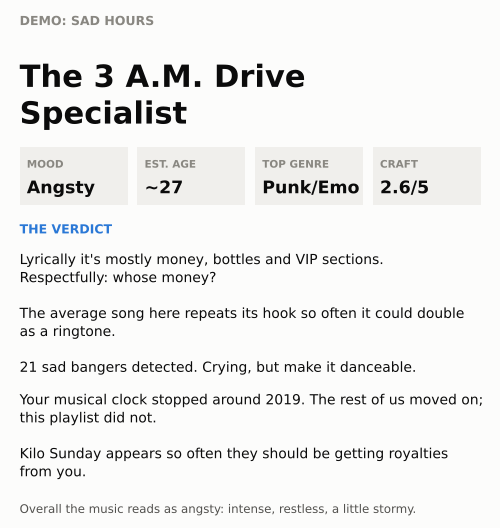

In [5]:
report.plot_card(profile);

## 4. Mood

Each track gets a point on Russell's **circumplex** (valence = sad to happy, arousal = calm to energetic), blending
audio valence/energy/tempo (weight 0.6 for valence), lyric emotion (0.3) and crowd tags (0.1), renormalised over
whatever is available. The playlist estimate is the mean with a bootstrap 90% interval.
**Sad bangers** are tracks whose lyrics read sad while the audio is danceable or energetic.

Saddest:


,name,artists,mood_valence,mood_arousal,valence,lyric_valence
25,Honey Glass,[Kilo Sunday],0.157639,0.610084,0.099148,0.274621
23,River Light,[Mara Lune],0.224881,0.383654,0.161708,0.351225
15,Signal Midnight,[Kilo Sunday],0.232907,0.639901,0.156327,0.386067


Happiest:


,name,artists,mood_valence,mood_arousal,valence,lyric_valence
9,Orchard Kitchen,[Neon Hymnal],0.812053,0.708654,0.799209,0.837741
49,Satellite Midnight,[Sable Nine],0.734238,0.796992,0.767838,0.667037
0,Echo Velvet,[Neon Hymnal],0.728878,0.654150,0.732586,0.721462


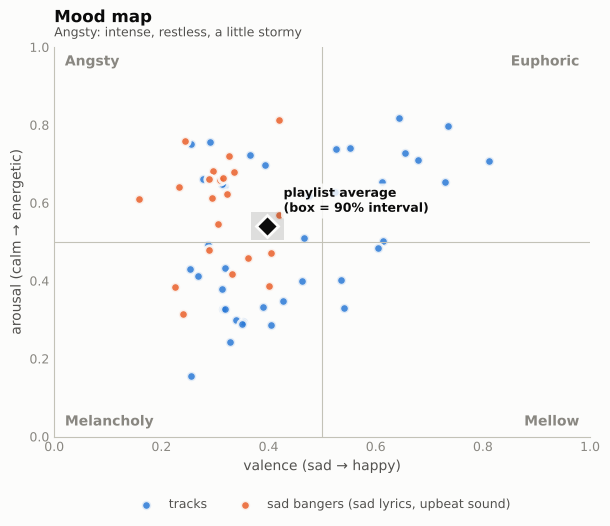

In [6]:
report.plot_mood_map(profile);
cols = ["name", "artists", "mood_valence", "mood_arousal", "valence", "lyric_valence"]
print("Saddest:");   display(profile.tracks.nsmallest(3, "mood_valence")[cols])
print("Happiest:");  display(profile.tracks.nlargest(3, "mood_valence")[cols])

## 5. How old does this playlist think you are?

The **reminiscence bump**: people's favourite music clusters around their teens and early twenties. The model
treats each album's release year as a mix of *formative-years music* (centred on birth year + 17),
*current releases* (any age listens to these) and *background* (classics, your parents' records). The mixture
weights are fitted for every candidate age, combined with a broad prior, and tempered because tracks aren't
independent. Section 9 shows how to calibrate it.

~27 years old (80% interval 24-30, from 37 release years)
mixture at the best-fitting age: {'formative years': 0.713, 'current releases': 0.191, 'everything else': 0.096}


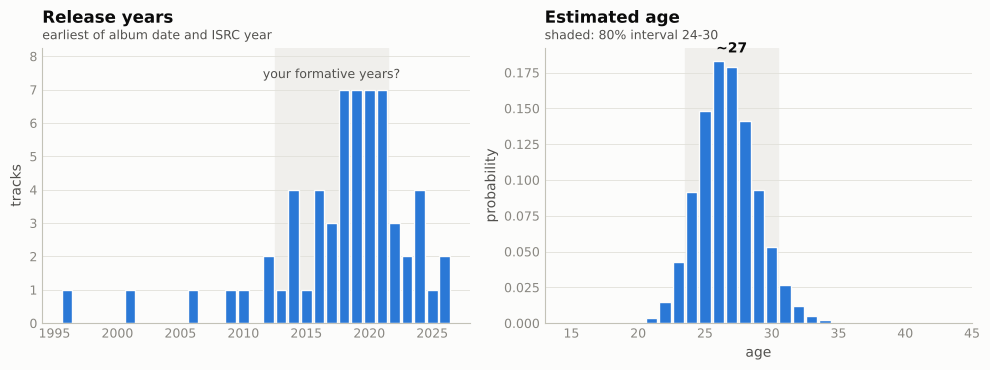

In [7]:
print(profile.age)
print("mixture at the best-fitting age:", profile.age.mixture)
report.plot_era(profile);

## 6. Listening personality

Macro genres map onto the **MUSIC** model of taste (Mellow, Unpretentious, Sophisticated, Intense, Contemporary;
Rentfrow et al., 2011). Persona = dominant dimension x mood quadrant. The Big Five hints come from published
correlations that are real but small (|r| around .1-.3), so read them as horoscope-grade.

The 3 A.M. Drive Specialist
 - People with this mix tend to score a bit higher on Extraversion.
 - People with this mix tend to score a bit higher on Openness.
craft score: 2.6 {'artist variety': 0, 'genre focus': 0.28, 'length': 1, 'mood coherence': 0.77}


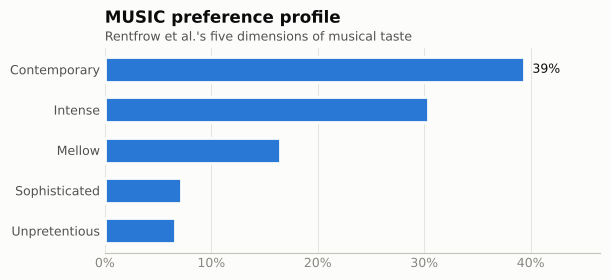

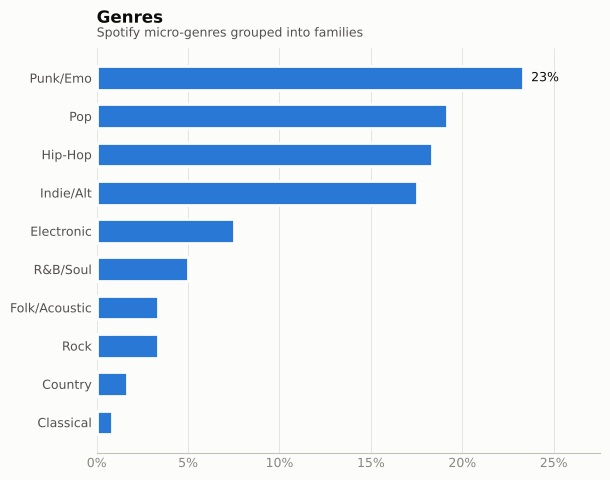

In [8]:
p = profile.personality
print(p.persona)
for h in p.trait_hints: print(" -", h)
print("craft score:", p.craft_score, {k: round(v, 2) for k, v in p.craft_breakdown.items()})
report.plot_music(profile);
report.plot_genres(profile);

## 7. Lyrics

Emotions over Ekman's six + neutral. With `pip install "vibecheck[nlp]"` this uses the
`j-hartmann/emotion-english-distilroberta-base` transformer on stanza chunks; otherwise an offline word-list +
VADER model. Themes are phrase lists (heartbreak, party & flex, nostalgia...) scored per 100 words.
Lyrics themselves are never displayed.

emotion backend: lexicon


,hits per 100 words
party & flex,4.51
love,1.95
nostalgia,1.20
heartbreak,1.12
loneliness,0.57
hope & growth,0.44
anger & defiance,0.23
anxiety & self-doubt,0.00
darkness,0.00
substances,0.00


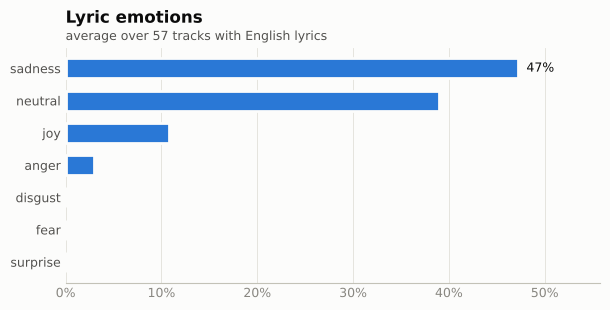

In [9]:
print("emotion backend:", profile.tracks.attrs.get("emotion_backend"))
report.plot_emotions(profile);
profile.features["themes"].round(2).rename("hits per 100 words").to_frame()

## 8. Emotional tone (descriptive, not diagnostic)

Signals describe the *music*. The most meaningful one needs history: a shift relative to **your own** baseline,
not a comparison against other people.

In [10]:
w = profile.wellbeing
print(w.tone)
display(pd.DataFrame([vars(s) for s in w.signals]))
print(w.disclaimer)
if w.check_in: print(w.check_in)

Overall the music reads as angsty: intense, restless, a little stormy.


,name,value,level,note
0,low-valence share,0.516667,elevated,share of tracks that sound and read as sad or dark
1,sad lyrics share,0.719298,elevated,share of lyric-bearing tracks where sadness is the leadi...
2,heavy lyrical themes,0.574889,typical,loneliness / anxiety / darkness words per 100 lyric words


These are patterns in the music, not a read on your mental health. Sad songs are often how people feel better, and a playlist can't tell the difference.
If things have actually felt heavy lately, talking to someone you trust (or a professional) will help more than any playlist.


## 9. Your listening history (optional)

Request **Extended streaming history** at spotify.com/account/privacy (takes a few days), then point
`load_streaming_history` at the zip. `analyze_history` enriches your most-played tracks (no Spotify login needed)
and adds: listening clock, skip and repeat rates, discovery rate, a year-by-year Wrapped table, and a weekly mood
timeline compared against your own trailing baseline.

In [11]:
if DEMO:
    hist = demo_history(tracks)
    hprofile = vc.analyze_history(hist, tz=TZ, tracks=tracks)   # demo: reuse the enriched demo tracks
else:
    hist = load_streaming_history("my_spotify_data.zip")
    hprofile = vc.analyze_history(hist, tz=TZ, top_n=300)

b = hprofile.behavior
print(f"{b.total_hours:,.0f} hours, {b.n_plays:,} streams, {b.first:%b %Y} to {b.last:%b %Y}")
print(f"night share {b.night_share:.0%} | skip rate {b.skip_rate:.0%} | same-day repeats {b.repeat_share:.0%} | first listens {b.discovery_share:.0%}")
print("peak binge:", b.peak_binge)
display(b.yearly)
for line in hprofile.roast: print(" *", line)

336 hours, 5,845 streams, Aug 2025 to Oct 2026
night share 5% | skip rate 22% | same-day repeats 30% | first listens 1%
peak binge: {'date': '2025-12-03', 'track': 'Velvet Ghost', 'artist': 'Sable Nine', 'plays': 6}


,year,hours,top_artist,top_track,unique_tracks
0,2025,99.3,Kilo Sunday,Ghost Ember,60
1,2026,230.4,Kilo Sunday,Ghost Ember,60


 * Lyrically it's mostly money, bottles and VIP sections. Respectfully: whose money?
 * The average song here repeats its hook so often it could double as a ringtone.
 * Only 1% of your plays were songs you'd never heard before. Comfort food, every meal.
 * 21 sad bangers detected. Crying, but make it danceable.
 * Your musical clock stopped around 2019. The rest of us moved on; this playlist did not.


trend vs your own baseline: {'recent': 0.3309004922736395, 'baseline': 0.3775672555965735, 'z': -3.004397865082106, 'periods': 26}


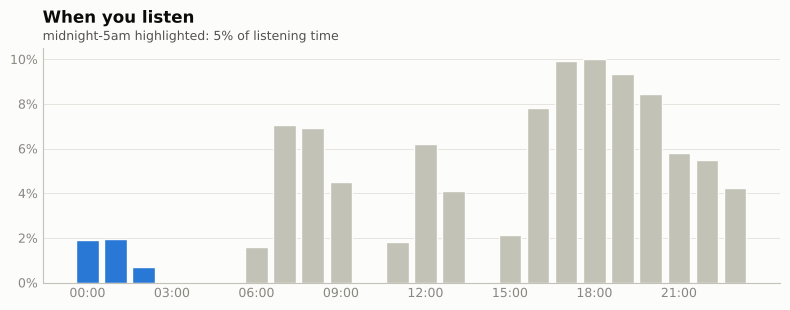

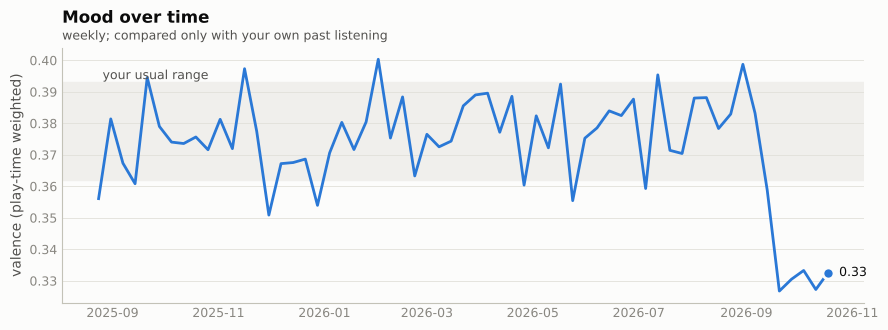

In [12]:
report.plot_listening_clock(hprofile);
report.plot_mood_timeline(hprofile);
print("trend vs your own baseline:", hprofile.wellbeing.trend)

## 10. ML, part A: a mood classifier trained on playlist titles

No hand labels: playlist titles like "sad hours", "GYM", "study" become **weak labels** for every track inside.
A logistic regression on audio + lyric + genre features is evaluated with **GroupKFold by playlist**, so tracks
from one playlist never appear in both train and test (that leak inflates scores badly).

Real data: your own playlists with mood-ish names (only those you own are readable in Development Mode), or
slices of the Spotify Million Playlist Dataset via `vibecheck.ml.load_mpd_slice`, enriched through ReccoBeats/LRCLIB
by track ID. **The demo numbers below are optimistic**: synthetic moods are cleanly separated and tied to genres.

In [13]:
from vibecheck.ml import build_dataset, train_mood_classifier, title_label

if DEMO:
    labelled = demo_labelled_playlists()
else:
    mine = vc.spotify.my_playlists()
    readable = mine[mine["readable"]]
    labelled = [(r.name, vc.spotify.playlist_tracks(r.playlist_id)) for r in readable.itertuples() if title_label(r.name)]

vc.verbose = False
enriched = [(title, vc.enrich(df)) for title, df in labelled]
vc.verbose = True
X, y, groups, used = build_dataset(enriched)
clf = train_mood_classifier(X, y, groups)
cv = clf.cv
print(f"{cv['n_tracks']} tracks from {cv['n_playlists']} playlists, {cv['folds']}-fold GroupKFold")
print(f"accuracy {cv['accuracy']:.2f} (majority baseline {cv['baseline_accuracy']:.2f}) | macro-F1 {cv['macro_f1']:.2f} (baseline {cv['baseline_macro_f1']:.2f})")
display(cv["confusion"])

1050 tracks from 42 playlists, 5-fold GroupKFold
accuracy 0.82 (majority baseline 0.14) | macro-F1 0.82 (baseline 0.04)


,angry,chill,focus,happy,hype,romantic,sad
angry,124,5,6,2,4,6,3
chill,3,116,7,8,5,5,6
focus,3,6,127,2,2,5,5
happy,3,2,5,121,6,4,9
hype,4,3,5,2,130,2,4
romantic,2,5,2,2,2,130,7
sad,9,4,7,5,5,9,111


In [14]:
display(clf.top_features(4))
print("Predicted mood mix for the playlist from section 1:")
clf.predict_playlist(profile.tracks).map("{:.0%}".format)

,mood,top features
0,angry,"tempo (+0.53), genre_Punk/Emo (+0.44), genre_Metal (+0.4..."
1,chill,"genre_Electronic (+0.81), lyric_valence (+0.30), livenes..."
2,focus,"genre_Classical (+0.84), instrumentalness (+0.46), emo_n..."
3,happy,"genre_Pop (+1.05), loudness (+0.38), theme_heartbreak (+..."
4,hype,"genre_Hip-Hop (+1.36), acousticness (+0.39), loudness (+..."
5,romantic,"genre_R&B/Soul (+0.73), theme_love (+0.32), genre_Hip-Ho..."
6,sad,"tempo (+0.60), genre_Folk/Acoustic (+0.45), genre_Indie/..."


Predicted mood mix for the playlist from section 1:


hype        31%
happy       29%
sad         14%
romantic     8%
angry        7%
chill        6%
focus        4%
dtype: str

**Look at that prediction.** The demo playlist is mostly sad-sounding, yet the classifier leans hype/happy. In
the synthetic training data every mood came with its own genres, so the model learned *genre shortcuts*
(see the top features: genre columns dominate). Real playlist titles invite the same failure. An ablation
without genre features shows how much of the score was the shortcut:

In [15]:
no_genre = [c for c in X.columns if not c.startswith("genre_")]
clf_ng = train_mood_classifier(X[no_genre], y, groups)
print(f"without genre features: macro-F1 {clf_ng.cv['macro_f1']:.2f} (with: {cv['macro_f1']:.2f})")
clf_ng.predict_playlist(profile.tracks).map("{:.0%}".format)

without genre features: macro-F1 0.79 (with: 0.82)


sad         33%
hype        23%
happy       13%
romantic    12%
angry       10%
chill        7%
focus        4%
dtype: str

## 11. ML, part B: calibrating the age model

The age model's constants (bump centre/width, tempering) are guesses until fitted on labelled data. `fit()` grid-
searches them by log loss; evaluate on held-out people with MAE and **80%-interval coverage** (should be near 0.8).
The demo samples come from a known process (true bump at 15 years, sd 4), so you can watch it recover them.
For real labels you'd need (playlist or top tracks, true age) pairs from consenting friends, which the 5-user cap
and CSV exports make possible on a small scale.

In [16]:
from vibecheck.analysis.age import AgeModel

train, test = demo_age_samples(100, seed=5), demo_age_samples(80, seed=6)
model = AgeModel()
before = model.score(test)
table = model.fit(train)
after = model.score(test)
print("before:", {k: round(v, 2) for k, v in before.items()})
print("after: ", {k: round(v, 2) for k, v in after.items()})
print("fitted: bump_age", model.bump_age, "bump_sd", model.bump_sd, "tempering_n", model.tempering_n)
table.head()

before: {'mae': 3.16, 'coverage80': 0.86, 'log_loss': 2.58, 'n': 80}
after:  {'mae': 1.66, 'coverage80': 0.85, 'log_loss': 1.88, 'n': 80}
fitted: bump_age 15.0 bump_sd 4.0 tempering_n 25.0


,bump_age,bump_sd,tempering_n,mae,coverage80,log_loss,n
0,15,4,25,2.10,0.87,1.827212,100
1,15,3,25,2.01,0.84,1.828060,100
2,15,5,25,2.30,0.89,1.930570,100
3,15,3,12,3.39,0.88,2.100671,100
4,15,4,12,3.31,0.88,2.153304,100


## 12. Save everything

In [17]:
paths = report.save_all(profile, "vibecheck_report")
paths

['vibecheck_report/card.png',
 'vibecheck_report/mood_map.png',
 'vibecheck_report/era.png',
 'vibecheck_report/genres.png',
 'vibecheck_report/music.png',
 'vibecheck_report/emotions.png']

## Where to take it next
- **Better mood ground truth:** have a few friends rate their own mood weekly while you log their listening;
  that turns "emotional tone" into something you can actually validate.
- **Swap the classifier:** gradient boosting or a small MLP on the same features; compare with GroupKFold.
- **Lyrics embeddings:** sentence-transformer embeddings of lyrics instead of word lists, then cluster.
- **An LLM roast:** pass `profile.features` + the rule-based lines to an LLM for funnier, less templated jokes.